# Dữ liệu Nile Sales có gì? (Phase 1, lượt chạy lại)

Chỉ đọc `data/Nile_Sales_YTD.xlsx`. Mỗi cell trả lời một câu hỏi rồi giải thích ngay dưới. Không sửa nguồn, không suy khóa nghiệp vụ.

In [1]:
import sys, platform
import pandas as pd, openpyxl
print('python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| openpyxl:', openpyxl.__version__)
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'Nile_Sales_YTD.xlsx').exists()))
DATA = ROOT / 'data' / 'Nile_Sales_YTD.xlsx'
import hashlib
sha_dau = hashlib.sha256(DATA.read_bytes()).hexdigest()
assert sha_dau == 'fae7a6955da3f3166ef4766d26acc39b8fed7b8c763e077a83c015a6d4fc0bd8', 'DUNG: hash nguon la'
print('SHA khớp dispatch, đọc tiếp.')
COLS = ['Sales_Date','Delivery_Date','SKU_Code','Qty','Unit_Price','Line_Amount','From_Location',
'To_Location','Channel','Sub_Channel','Delivery_Type','Courier','City_Tier','Category','Order_ID','Customer_ID','Payment_Method','Is_Returned']
SHEETS = {'Nile_Sales_2025-07': 1722, 'Nile_Sales_2025-06': 1597, 'Nile_Sales_2025-05': 1473, 'Nile_Sales_2025-04': 1376, 'Nile_Sales_2025-03': 1276, 'Nile_Sales_2025-02': 1167, 'Nile_Sales_2025-01': 1094}
import matplotlib
matplotlib.rcParams['figure.dpi'] = 100
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


python: 3.10.11
pandas: 2.2.3 | openpyxl: 3.1.5
SHA khớp dispatch, đọc tiếp.


### Nguồn có đúng bản cần kiểm?

**Giải thích:** phiên bản thư viện và hash nguồn khớp bản được chấp nhận (dispatch.acceptedSourceRevision) thì làm tiếp; lệch thì dừng. Chi tiết môi trường/log dài nằm ở evidence, không làm rối người đọc.

In [2]:
wb = openpyxl.load_workbook(DATA, read_only=True, data_only=True)
assert sorted(wb.sheetnames) == sorted(SHEETS)
for ten in wb.sheetnames:
    dong = list(wb[ten].iter_rows(values_only=True))
    assert len(dong[0]) == 18 and list(dong[0]) == COLS
    dem = sum(1 for r in dong[1:] if any(v is not None for v in r))
    assert dem == SHEETS[ten], f'DUNG sheet {ten}'
    print(f'{ten}: {dem} dòng — KHỚP')
wb.close()
print('Tổng 9.705 dòng; 7 sheet cùng 18 cột.')


Nile_Sales_2025-07: 1722 dòng — KHỚP
Nile_Sales_2025-06: 1597 dòng — KHỚP


Nile_Sales_2025-05: 1473 dòng — KHỚP
Nile_Sales_2025-04: 1376 dòng — KHỚP


Nile_Sales_2025-03: 1276 dòng — KHỚP
Nile_Sales_2025-02: 1167 dòng — KHỚP


Nile_Sales_2025-01: 1094 dòng — KHỚP
Tổng 9.705 dòng; 7 sheet cùng 18 cột.


### 7 sheet có đủ dòng và cùng schema?

**Giải thích:** đủ 7 sheet, số dòng từng sheet khớp dispatch, header 18 cột giống nhau. Đây là đếm đầu vào, chưa kết luận dòng hợp lệ.

In [3]:
khung_tung_sheet = []
for ten in SHEETS:
    bang = pd.read_excel(DATA, sheet_name=ten, engine='openpyxl')
    bang['__source_file__'] = 'data/Nile_Sales_YTD.xlsx'
    bang['__sheet__'] = ten
    bang['__excel_row__'] = bang.index + 2
    khung_tung_sheet.append(bang)
du_lieu = pd.concat(khung_tung_sheet, ignore_index=True)
ma_truy = du_lieu['__source_file__'] + '|' + du_lieu['__sheet__'] + '|' + du_lieu['__excel_row__'].astype(str)
assert len(du_lieu) == 9705 and ma_truy.is_unique
print('Bảng gộp:', du_lieu.shape, '| mã truy nguồn duy nhất.')


Bảng gộp: (9705, 21) | mã truy nguồn duy nhất.


### Một dòng được truy lại bằng gì?

**Giải thích:** gộp 7 sheet thành một bảng, mỗi dòng giữ địa chỉ tệp/sheet/số dòng Excel để truy lại ô gốc. Mã này là kỹ thuật, chưa phải khóa nghiệp vụ.

## Hiểu bản chất dữ liệu (đọc chính ở docs/01_data_understanding.md)

**Một dòng là gì (mức quan sát):** mỗi dòng ghi một SKU bán ra với số lượng, đơn giá, giá trị của dòng đó — thấy qua `SKU_Code`, `Qty`, `Unit_Price`, `Line_Amount` (công thức khớp 100%). **Mã đơn khác đơn thật:** `Order_ID` là mã ghi trong nguồn, chưa xác nhận là đơn hàng kinh doanh hay khóa duy nhất. **Ngày/điểm giữ theo mã, khách/thanh toán/cờ đổi theo dòng** (chi tiết bên dưới). Nguồn file: subset thực hành lấy từ video Goodly (không truy được hệ thống; mô tả video xác nhận bộ thực hành, chưa xác nhận cách tạo hay giao dịch thật) — nguyên nhân các mẫu sau chưa xác minh, không loại trừ dữ liệu tạo/điều chỉnh.

In [4]:
co_don = du_lieu.groupby('Order_ID').size()
phan_bo_co = co_don.value_counts().sort_index()
print('Số dòng theo mã:', phan_bo_co.to_dict())
print(f"Mã 1 dòng: {int(phan_bo_co.get(1, 0))} | mã 2 dòng: {int(phan_bo_co.get(2, 0))} / {len(co_don)} mã")
assert set(phan_bo_co.index) == {1, 2}, 'DUNG: co ma hon 2 dong'
assert int(phan_bo_co.sum()) == 6246


Số dòng theo mã: {1: 2787, 2: 3459}
Mã 1 dòng: 2787 | mã 2 dòng: 3459 / 6246 mã


**Giải thích:** không có mã nào quá 2 dòng — dữ liệu chỉ gồm mã 1 dòng (2.787) và mã 2 dòng (3.459). Đây là hình dạng toàn bộ file, không phải mẫu lẻ.

Trong 3.459 mã 2 dòng: 3459 mã có 2 SKU khác + 3459 mã có 2 khách khác
Cặp mã đơn + mã khách: 9705 nhóm, lặp: 0
Tỷ lệ mã đa khách từng tháng:
thang
2025-01    0.562857
2025-02    0.543651
2025-03    0.563725
2025-04    0.560091
2025-05    0.547269
2025-06    0.551992
2025-07    0.549955
Ghép Sales_Date vào mã: vẫn 3459 nhóm đa khách
Ghép From_Location vào mã: vẫn 3459 nhóm đa khách
Ghép To_Location vào mã: vẫn 3459 nhóm đa khách
Ghép Channel vào mã: vẫn 3459 nhóm đa khách


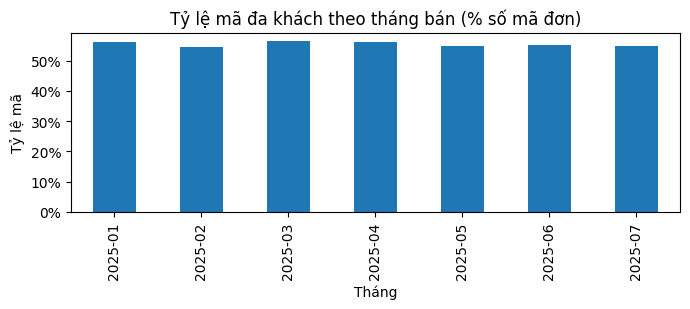

   Order_ID Customer_ID SKU_Code Sales_Date Payment_Method          __sheet__  __excel_row__
NILE-200004      M82012 BPC-1021 2025-01-01            COD Nile_Sales_2025-01              5
NILE-200004      M74096 BPC-1022 2025-01-01        Prepaid Nile_Sales_2025-01              6


In [5]:
mau_2_dong = du_lieu[du_lieu.Order_ID.isin(co_don[co_don == 2].index)]
hai_sku = int((mau_2_dong.groupby('Order_ID').SKU_Code.nunique() == 2).sum())
hai_khach = int((mau_2_dong.groupby('Order_ID').Customer_ID.nunique() == 2).sum())
print(f'Trong 3.459 mã 2 dòng: {hai_sku} mã có 2 SKU khác + {hai_khach} mã có 2 khách khác')
assert hai_sku == hai_khach == 3459
cap_don_khach = du_lieu.groupby(['Order_ID', 'Customer_ID']).size()
print(f'Cặp mã đơn + mã khách: {len(cap_don_khach)} nhóm, lặp: {int((cap_don_khach > 1).sum())}')
thang_cua_dong = pd.to_datetime(du_lieu.Sales_Date).dt.strftime('%Y-%m')
ty_le_thang = du_lieu.assign(thang=thang_cua_dong).groupby('thang').apply(
    lambda g: (g.groupby('Order_ID').Customer_ID.nunique() > 1).mean(), include_groups=False)
print('Tỷ lệ mã đa khách từng tháng:')
print(ty_le_thang.to_string())
for cot in ['Sales_Date', 'From_Location', 'To_Location', 'Channel']:
    con = int((du_lieu.groupby(['Order_ID', cot]).Customer_ID.nunique() > 1).sum())
    print(f'Ghép {cot} vào mã: vẫn {con} nhóm đa khách')
    assert con == 3459
ax = (ty_le_thang * 100).plot(kind='bar', figsize=(7, 3.2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0f}%'))
ax.set_title('Tỷ lệ mã đa khách theo tháng bán (% số mã đơn)')
ax.set_xlabel('Tháng'); ax.set_ylabel('Tỷ lệ mã')
plt.tight_layout(); plt.show()
vd = du_lieu[du_lieu.Order_ID == 'NILE-200004'][['Order_ID','Customer_ID','SKU_Code','Sales_Date','Payment_Method','__sheet__','__excel_row__']]
print(vd.to_string(index=False))


**Giải thích:** toàn bộ 3.459 mã 2 dòng đều là 2 SKU khác + 2 khách khác — mẫu tuyệt đối, lặp cả 7 tháng (54–56%). Ghép thêm ngày/kho/nơi nhận/kênh vào mã vẫn còn nguyên 3.459 nhóm đa khách nên không giải quyết bằng không gian tên quan sát. Ví dụ gốc NILE-200004 (sheet Jan, dòng 5–6): cùng ngày/điểm, khác khách/SKU/thanh toán — notebook không tạo ra mẫu này. Diễn giải đầy đủ ở docs/01_data_understanding.md.

In [6]:
thang_cua_ma = pd.to_datetime(du_lieu.drop_duplicates('Order_ID').set_index('Order_ID').Sales_Date).dt.strftime('%Y-%m')
so_ma_thang = thang_cua_ma.value_counts().sort_index()
quy_luat = {f'2025-{t:02d}': round(700 * 1.08 ** i) for i, t in enumerate(range(1, 8))}
print('Mã nguồn từng tháng:', so_ma_thang.to_dict())
print('Quy luật round(700*1.08^i):', quy_luat)
assert so_ma_thang.to_dict() == quy_luat, 'DỪNG: số mã tháng lệch quy luật'
print('Khớp quy luật làm tròn +8%/tháng — mẫu quan sát, không chứng minh cách sinh hay tăng trưởng thật.')


Mã nguồn từng tháng: {'2025-01': 700, '2025-02': 756, '2025-03': 816, '2025-04': 882, '2025-05': 952, '2025-06': 1029, '2025-07': 1111}
Quy luật round(700*1.08^i): {'2025-01': 700, '2025-02': 756, '2025-03': 816, '2025-04': 882, '2025-05': 952, '2025-06': 1029, '2025-07': 1111}
Khớp quy luật làm tròn +8%/tháng — mẫu quan sát, không chứng minh cách sinh hay tăng trưởng thật.


**Giải thích:** số mã nguồn từng tháng (700→1.111) khớp công thức làm tròn tăng 8% — đều đặn như số mã 2 dòng tuyệt đối. Đây là dấu hiệu phù hợp với dữ liệu tạo/điều chỉnh cho bài tập, nhưng khớp công thức không chứng minh thuật toán sinh, cũng không phải tăng trưởng kinh doanh thật.

In [7]:
dong_bi_anh_huong = int((co_don[du_lieu.Order_ID] > 1).sum())
print(f'Dòng trong mã đa khách: {dong_bi_anh_huong}/{len(du_lieu)} = {dong_bi_anh_huong/len(du_lieu)*100:.1f}%')
assert dong_bi_anh_huong == 6918
print(f'Đếm mã nguồn: {len(co_don)} | nếu tự coi cặp đơn+khách là đơn mới: {len(cap_don_khach)} (minh họa, KHÔNG áp dụng)')
print(f"Mã 1 dòng giữ {int(phan_bo_co.get(1, 0))} dòng; bỏ dòng theo mã sẽ mất dòng sản phẩm của mã 2 dòng")


Dòng trong mã đa khách: 6918/9705 = 71.3%
Đếm mã nguồn: 6246 | nếu tự coi cặp đơn+khách là đơn mới: 9705 (minh họa, KHÔNG áp dụng)
Mã 1 dòng giữ 2787 dòng; bỏ dòng theo mã sẽ mất dòng sản phẩm của mã 2 dòng


**Giải thích:** mẫu ảnh hưởng 6.918/9.705 = 71,3% dòng — mọi chỉ số theo mã đơn đều đứng trên nền này. Đếm mã nguồn (6.246) chưa phải số đơn thật; tự nhận cặp đơn+khách là đơn mới sẽ đổi số đếm lên 9.705, lấy khách đầu tiên/gộp 2 khách hay bỏ dòng đều là sửa dữ liệu — không làm khi chưa rõ. Dùng được: mô tả dòng/giá trị nguồn có giới hạn; chưa phân tích khách, doanh thu thuần, giao đúng hạn.

**Giả thuyết xếp theo mức phù hợp (chưa xác minh, không suy nguyên nhân từ 55%):**
H1 — dữ liệu tạo/điều chỉnh cho bài tập, khách gán theo từng dòng (phù hợp nhất hiện tại): giải thích mẫu tuyệt đối 2 dòng/2 khách, quy luật tháng +8%, 4 cột kênh/vận chuyển đơn trị. Chưa chứng minh cách tạo.
H2 — ánh xạ mã khách sai khi tạo/xuất (ngày/tuyến giữ, khách sai): phù hợp ngày/điểm khớp; khác lỗi nối bảng nhân dòng vì không có cặp đơn+SKU lặp. Cần trường mapping/nguồn để phân biệt với H1.
H3 — mã gom nhiều giao dịch (cùng ngày/tuyến, khác khách/thanh toán): phù hợp bề mặt; thiếu định nghĩa gom, tối đa 2 dòng không tự chứng minh gom hàng.
H4 — trùng mã giữa các nguồn khác nhau: ít phù hợp nhất vì ngày/tuyến trùng khít, nhưng chưa loại trừ khi thiếu namespace.

**Việc xác minh ưu tiên:** xem bộ thực hành/giải thích của tác giả video (không truy hệ thống, không liên hệ/form/tải thêm); giữ Order_ID như mã nhóm nguồn; không gộp/chọn khách, không tạo khóa, không bỏ dòng. Giả định để thực hành chỉ là đề xuất, chưa được duyệt.

**H1 đã được người dùng chốt làm giả định thực hành** (chưa phải nguyên nhân thật đã chứng minh): giữ `Order_ID` như mã nhóm nguồn và mọi dòng/khách; giá trị đơn bình quân cần định nghĩa mã đơn và giá trị trước, không tự suy từ mã khách, không nhận bình quân mã nhóm là AOV nghiệp vụ.

In [8]:
from collections import Counter
wb = openpyxl.load_workbook(DATA, read_only=True, data_only=True)
kieu_o_goc = {}
for ten in wb.sheetnames:
    dong = list(wb[ten].iter_rows(values_only=False))
    hop_le = [r for r in dong[1:] if any(o.value is not None for o in r)]
    for i, ten_cot in enumerate([o.value for o in dong[0]]):
        dem_kieu = kieu_o_goc.setdefault(ten_cot, Counter())
        for r in hop_le:
            v = r[i].value
            if v is None: dem_kieu['NULL'] += 1
            elif isinstance(v, bool): dem_kieu['bool'] += 1
            elif isinstance(v, str) and v.strip() == '': dem_kieu['TRONG'] += 1
            else: dem_kieu[type(v).__name__] += 1
wb.close()
for ten_cot in COLS:
    print(f'{ten_cot}: {dict(kieu_o_goc[ten_cot])}')
tron = [k for k, v in kieu_o_goc.items() if len([t for t in v if t not in ('NULL', 'TRONG')]) > 1]
assert not tron and sum(v.get('NULL', 0) for v in kieu_o_goc.values()) == 0
print('Không trộn kiểu, không NULL, không chuỗi rỗng.')


Sales_Date: {'datetime': 9705}
Delivery_Date: {'datetime': 9705}
SKU_Code: {'str': 9705}
Qty: {'int': 9705}
Unit_Price: {'int': 9705}
Line_Amount: {'int': 9705}
From_Location: {'str': 9705}
To_Location: {'str': 9705}
Channel: {'str': 9705}
Sub_Channel: {'str': 9705}
Delivery_Type: {'str': 9705}
Courier: {'str': 9705}
City_Tier: {'str': 9705}
Category: {'str': 9705}
Order_ID: {'str': 9705}
Customer_ID: {'str': 9705}
Payment_Method: {'str': 9705}
Is_Returned: {'int': 9705}
Không trộn kiểu, không NULL, không chuỗi rỗng.


### Kiểu dữ liệu gốc có sạch?

**Giải thích:** đếm kiểu từng ô Excel gốc thay vì chỉ nhìn kiểu pandas suy ra. Ngày toàn datetime, số/cờ toàn int, chuỗi toàn str — sạch ở mức ô, không thiếu, không lẫn kiểu.

In [9]:
trung_full = du_lieu.duplicated(subset=COLS, keep='first').sum()
print('Dòng trùng đầy đủ (bản thừa):', int(trung_full))
nhom_don = du_lieu.groupby('Order_ID').size()
print(f'Mã đơn: {len(nhom_don)} mã khác nhau; {int((nhom_don > 1).sum())} mã có nhiều dòng')
nhom_don_sku = du_lieu.groupby(['Order_ID', 'SKU_Code']).size()
print(f'Cặp mã đơn + SKU: {len(nhom_don_sku)} nhóm, lặp: {int((nhom_don_sku > 1).sum())}')
assert int(trung_full) == 0


Dòng trùng đầy đủ (bản thừa): 0
Mã đơn: 6246 mã khác nhau; 3459 mã có nhiều dòng
Cặp mã đơn + SKU: 9705 nhóm, lặp: 0


### Có trùng dòng, khóa quan sát là gì?

**Giải thích:** không dòng nào trùng đầy đủ. Một mã đơn có thể nhiều dòng (6.246 mã/9.705 dòng); cặp mã đơn+SKU không lặp trong snapshot — mới là quan sát, chưa đủ gọi là khóa nghiệp vụ.

Một khách: 2787 mã | Nhiều khách: 3459 mã


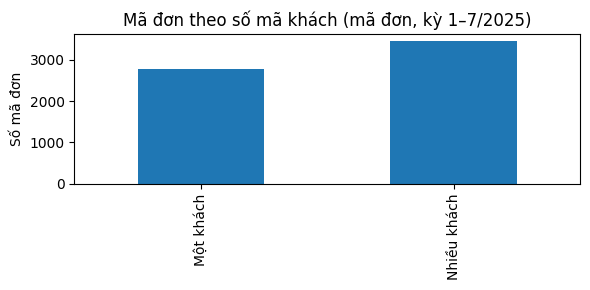

   Order_ID Customer_ID SKU_Code          __sheet__  __excel_row__
NILE-200004      M82012 BPC-1021 Nile_Sales_2025-01              5
NILE-200004      M74096 BPC-1022 Nile_Sales_2025-01              6


In [10]:
so_khach_theo_don = du_lieu.groupby('Order_ID')['Customer_ID'].nunique()
don_nhieu_khach = so_khach_theo_don[so_khach_theo_don > 1]
don_mot_khach = (so_khach_theo_don == 1).sum()
print(f'Một khách: {don_mot_khach} mã | Nhiều khách: {len(don_nhieu_khach)} mã')
ax = pd.Series({'Một khách': don_mot_khach, 'Nhiều khách': len(don_nhieu_khach)}).plot(kind='bar', figsize=(6, 3))
ax.set_title('Mã đơn theo số mã khách (mã đơn, kỳ 1–7/2025)')
ax.set_ylabel('Số mã đơn')
plt.tight_layout(); plt.show()
print(du_lieu[du_lieu.Order_ID == don_nhieu_khach.index[0]][['Order_ID','Customer_ID','SKU_Code','__sheet__','__excel_row__']].to_string(index=False))


### Bất nhất đơn–khách lớn cỡ nào?

**Giải thích:** hơn một nửa mã đơn (3.459/6.246) gắn nhiều mã khách — ví dụ một mã có hai dòng, hai mã khách khác nhau. Đây là bất nhất cần hỏi chủ dữ liệu, không tự gộp/sửa khách, không dùng phân tích khách hàng hay giá trị đơn bình quân.

In [11]:
for thuoc_tinh in ['Sales_Date','Delivery_Date','From_Location','To_Location','Payment_Method','Is_Returned']:
    so_don = int((du_lieu.groupby('Order_ID')[thuoc_tinh].nunique() > 1).sum())
    print(f'{thuoc_tinh}: {so_don} mã đơn có hơn 1 giá trị')


Sales_Date: 0 mã đơn có hơn 1 giá trị
Delivery_Date: 0 mã đơn có hơn 1 giá trị
From_Location: 0 mã đơn có hơn 1 giá trị
To_Location: 0 mã đơn có hơn 1 giá trị
Payment_Method: 1822 mã đơn có hơn 1 giá trị
Is_Returned: 372 mã đơn có hơn 1 giá trị


### Thuộc tính theo mã đơn có nhất quán?

**Giải thích:** ngày và điểm gửi/nhận nhất quán theo mã đơn; chỉ thanh toán (1.822) và cờ hoàn (372) khác nhau trong cùng mã. Vì vậy mã đơn chưa phải đơn vị tính ổn định cho giá trị hay hoàn.

Không đọc được (bán/giao): 0 / 0
Bán: 2025-01-01 → 2025-07-31 | giao: 2025-01-03 → 2025-08-06
Giao trước bán: 0
Số ngày có dòng bán: 212


Tháng trong tên sheet khớp 100% tháng ngày bán.


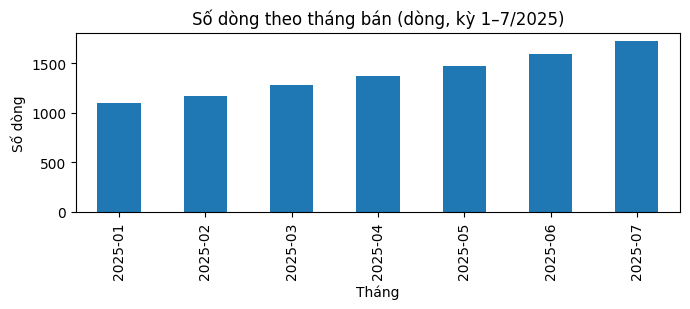

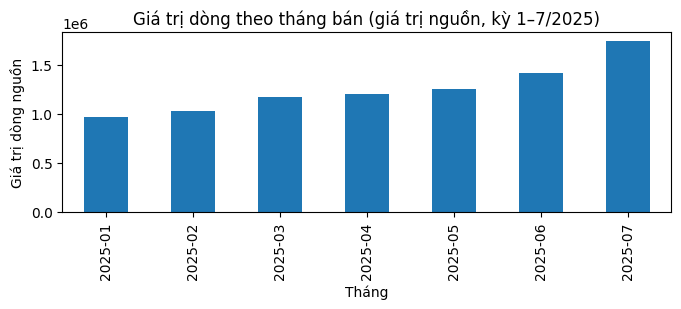

In [12]:
ngay_ban = pd.to_datetime(du_lieu.Sales_Date, errors='coerce')
ngay_giao = pd.to_datetime(du_lieu.Delivery_Date, errors='coerce')
print('Không đọc được (bán/giao):', int(ngay_ban.isna().sum()), '/', int(ngay_giao.isna().sum()))
print('Bán:', ngay_ban.min().date(), '→', ngay_ban.max().date(), '| giao:', ngay_giao.min().date(), '→', ngay_giao.max().date())
print('Giao trước bán:', int(((ngay_giao < ngay_ban) & ngay_ban.notna() & ngay_giao.notna()).sum()))
print('Số ngày có dòng bán:', int(ngay_ban.dt.date.nunique()))
dem_thang = ngay_ban.dt.to_period('M').value_counts().sort_index()
du_lieu['__thang__'] = ngay_ban.dt.strftime('%Y-%m')
for ten in sorted(du_lieu.__sheet__.unique()):
    assert sorted(du_lieu[du_lieu.__sheet__ == ten].__thang__.unique()) == [ten.split('_')[-1]]
print('Tháng trong tên sheet khớp 100% tháng ngày bán.')
ax = dem_thang.plot(kind='bar', figsize=(7, 3.2))
ax.set_title('Số dòng theo tháng bán (dòng, kỳ 1–7/2025)')
ax.set_xlabel('Tháng'); ax.set_ylabel('Số dòng')
plt.tight_layout(); plt.show()
tong_gia_tri_thang = du_lieu.groupby('__thang__').Line_Amount.sum()
ax = tong_gia_tri_thang.plot(kind='bar', figsize=(7, 3.2))
ax.set_title('Giá trị dòng theo tháng bán (giá trị nguồn, kỳ 1–7/2025)')
ax.set_xlabel('Tháng'); ax.set_ylabel('Giá trị dòng nguồn')
plt.tight_layout(); plt.show()


### Ngày có hợp lệ, phủ ra sao?

**Giải thích:** ngày đọc được toàn bộ, không giao trước bán; 212 ngày đều có dòng nhưng đủ ngày không chứng minh đủ giao dịch. Số dòng và giá trị đều tăng dần tới tháng 7 — mô tả xu hướng nguồn, chưa suy nguyên nhân. Ngày giao muộn nhất 06/08/2025; MAX ngày bán không phải ngày trích xuất.

In [13]:
thang_dong = du_lieu.assign(thang=pd.to_datetime(du_lieu.Sales_Date).dt.strftime('%Y-%m')).groupby('thang').agg(dong=('Qty', 'size'), luong=('Qty', 'sum'), tri=('Line_Amount', 'sum')).sort_index()
print(thang_dong.to_string())
dau = thang_dong.loc['2025-01']
cuoi = thang_dong.loc['2025-07']
print('T7 so T1: dong x' + str(round(cuoi.dong / dau.dong, 2)) + ' | luong x' + str(round(cuoi.luong / dau.luong, 2)) + ' | tri x' + str(round(cuoi.tri / dau.tri, 2)))
print('Tri/dong T1 ' + str(int(dau.tri / dau.dong)) + ' -> T7 ' + str(int(cuoi.tri / cuoi.dong)) + ' (chia mo ta)')


         dong  luong      tri
thang                        
2025-01  1094   1472   968478
2025-02  1167   1562  1031819
2025-03  1276   1746  1170399
2025-04  1376   1859  1197475
2025-05  1473   1956  1253697
2025-06  1597   2182  1421195
2025-07  1722   2310  1744028
T7 so T1: dong x1.57 | luong x1.57 | tri x1.8
Tri/dong T1 885 -> T7 1012 (chia mo ta)


**Giải thích:** lượng và giá trị theo tháng, so tháng 7 với tháng 1 trên cả khối lượng (dòng, Qty) và giá trị. Quy luật +8% số mã là mẫu quan sát, không phải tăng trưởng thật.

Khoảng bán–giao (ngày): min 2 | trung vị 3.0 | max 6


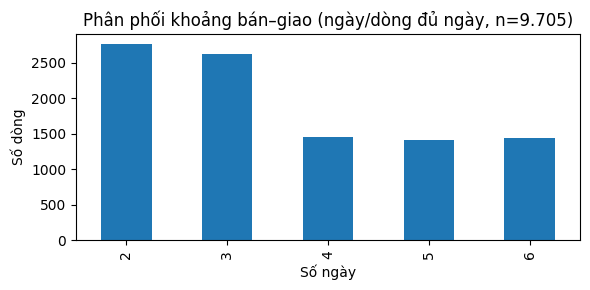

In [14]:
hieu_ngay = (ngay_giao - ngay_ban).dt.days
print('Khoảng bán–giao (ngày): min', int(hieu_ngay.min()), '| trung vị', float(hieu_ngay.median()), '| max', int(hieu_ngay.max()))
ax = hieu_ngay.value_counts().sort_index().plot(kind='bar', figsize=(6, 3))
ax.set_title('Phân phối khoảng bán–giao (ngày/dòng đủ ngày, n=9.705)')
ax.set_xlabel('Số ngày'); ax.set_ylabel('Số dòng')
plt.tight_layout(); plt.show()


### Khoảng bán–giao phân phối thế nào?

**Giải thích:** khoảng cách chỉ nhận giá trị 2–6 ngày, tập trung 2–3 ngày, trung vị 3. Ngày giao chưa rõ thực tế hay dự kiến nên chưa đánh giá giao đúng hạn.

In [15]:
khoang = (pd.to_datetime(du_lieu.Delivery_Date) - pd.to_datetime(du_lieu.Sales_Date)).dt.days
theo_noi = du_lieu.assign(k=khoang).groupby('To_Location').k.agg(['count', 'median']).sort_values('median')
print(theo_noi.head(3).to_string())
print(theo_noi.tail(3).to_string())
for noi in ['Kolkata', 'Bengaluru']:
    r = theo_noi.loc[noi]
    print(noi + ': n=' + str(int(r['count'])) + ', trung vi=' + str(r['median']))
print('Trung vị tính lại trên tập chung, không cộng trung vị nhóm.')


             count  median
To_Location               
Agra           193     3.0
Surat          229     3.0
Pune           685     3.0
             count  median
To_Location               
Bhopal         224     5.0
Patna          194     5.0
Indore         216     5.0
Kolkata: n=727, trung vi=5.0
Bengaluru: n=749, trung vi=3.0
Trung vị tính lại trên tập chung, không cộng trung vị nhóm.


**Giải thích:** bảng cho trung vị/số mẫu khoảng bán–giao theo nơi nhận (ví dụ Kolkata, Bengaluru). Chưa nhận ngày thực tế, đúng hạn, chậm hay nguyên nhân khi thiếu định nghĩa/chuẩn.

Qty: null 0 | =0: 0 | âm: 0 | min 1 | max 3
Unit_Price: null 0 | =0: 0 | âm: 0 | min 242 | max 1778
Line_Amount: null 0 | =0: 0 | âm: 0 | min 246 | max 4752
Khớp Qty × giá: 9705/9.705 | lệch: 0
Tổng Qty (mô tả nguồn): 13087.0 | tổng giá trị (đơn vị tiền chưa rõ): 8787091.0


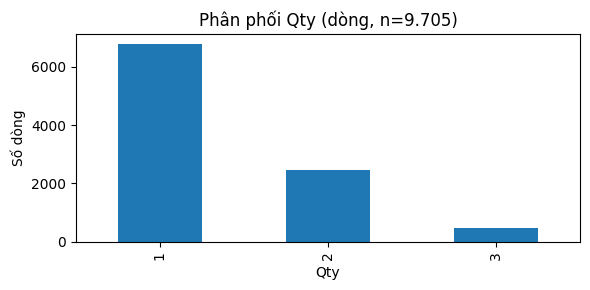

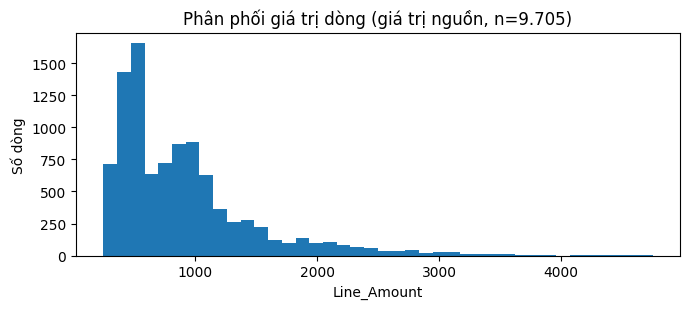

In [16]:
for ten_cot in ['Qty', 'Unit_Price', 'Line_Amount']:
    so = pd.to_numeric(du_lieu[ten_cot], errors='coerce')
    print(f"{ten_cot}: null {int(so.isna().sum())} | =0: {int((so == 0).sum())} | âm: {int((so < 0).sum())} | min {so.min()} | max {so.max()}")
so_luong = pd.to_numeric(du_lieu.Qty); don_gia = pd.to_numeric(du_lieu.Unit_Price); gia_tri = pd.to_numeric(du_lieu.Line_Amount)
chenh = (gia_tri - so_luong * don_gia).abs()
print(f'Khớp Qty × giá: {int((chenh < 0.005).sum())}/9.705 | lệch: {int((chenh >= 0.005).sum())}')
assert int((chenh >= 0.005).sum()) == 0
print('Tổng Qty (mô tả nguồn):', float(so_luong.sum()), '| tổng giá trị (đơn vị tiền chưa rõ):', float(gia_tri.sum()))
ax = so_luong.value_counts().sort_index().plot(kind='bar', figsize=(6, 3))
ax.set_title('Phân phối Qty (dòng, n=9.705)')
ax.set_xlabel('Qty'); ax.set_ylabel('Số dòng')
plt.tight_layout(); plt.show()
ax = gia_tri.plot(kind='hist', bins=40, figsize=(7, 3.2))
ax.set_title('Phân phối giá trị dòng (giá trị nguồn, n=9.705)')
ax.set_xlabel('Line_Amount'); ax.set_ylabel('Số dòng')
plt.tight_layout(); plt.show()


### Lượng và giá trị có đúng?

**Giải thích:** ba cột số nguyên sạch, `Qty` chỉ 1–3, công thức dòng đúng toàn bộ. Tổng chỉ mô tả nguồn; chưa gọi doanh thu vì đơn vị tiền/thuế/chiết khấu chưa rõ.

Giá trị cờ lạ ngoài 0–1: không có
Thiếu cờ: 0
Tử 574 / mẫu 9705 = 5.91% (mức dòng)


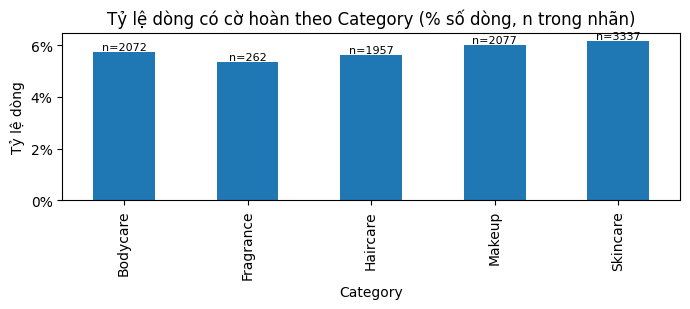

SKU→Category: mỗi SKU một nhóm (50 SKU về 5 Category: nhiều–một, trên giá trị quan sát).
Channel chỉ có: ['Nile'] → không so sánh được
Sub_Channel chỉ có: ['Nile'] → không so sánh được
Delivery_Type chỉ có: ['Scheduled'] → không so sánh được
Courier chỉ có: ['Nile Logistics'] → không so sánh được


In [17]:
co_hop_le = du_lieu.Is_Returned.isin([0, 1])
print('Giá trị cờ lạ ngoài 0–1:', sorted(set(du_lieu.loc[~co_hop_le, 'Is_Returned'])) or 'không có')
print('Thiếu cờ:', int((~co_hop_le).sum()))
mau_hop_le = int(co_hop_le.sum()); so_co_1 = int((du_lieu.Is_Returned == 1).sum())
ty_le = so_co_1 / mau_hop_le
print(f'Tử {so_co_1} / mẫu {mau_hop_le} = {ty_le:.2%} (mức dòng)')
ty_le_nhom = du_lieu[co_hop_le].groupby('Category').Is_Returned.mean()
so_mau_nhom = du_lieu[co_hop_le].groupby('Category').size()
ax = ty_le_nhom.plot(kind='bar', figsize=(7, 3.2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.set_title('Tỷ lệ dòng có cờ hoàn theo Category (% số dòng, n trong nhãn)')
ax.set_xlabel('Category'); ax.set_ylabel('Tỷ lệ dòng')
for i, (nhom, n) in enumerate(so_mau_nhom.items()):
    ax.text(i, ty_le_nhom[nhom], f'n={n}', ha='center', va='bottom', fontsize=8)
plt.tight_layout(); plt.show()
print('SKU→Category: mỗi SKU một nhóm (50 SKU về 5 Category: nhiều–một, trên giá trị quan sát).')
for ten_cot in ['Channel', 'Sub_Channel', 'Delivery_Type', 'Courier']:
    print(f'{ten_cot} chỉ có: {du_lieu[ten_cot].unique().tolist()} → không so sánh được')


### Cờ hoàn và nhóm hàng ra sao?

**Giải thích:** mặt nạ cờ hợp lệ 0–1 cho mẫu 9.705, tử 574, không thiếu/khác; tỷ lệ 5,91% là mức dòng, không phải tỷ lệ đơn hoàn. Theo nhóm, tỷ lệ quanh 5–6% với mẫu ghi trên cột. Bốn cột kênh/vận chuyển đơn trị nên chỉ báo, không vẽ, không so sánh.

In [18]:
co_thang = du_lieu.assign(thang=pd.to_datetime(du_lieu.Sales_Date).dt.strftime('%Y-%m')).groupby('thang').Is_Returned.agg(co1=lambda s: int((s == 1).sum()), mau='size')
co_thang['ty_le'] = co_thang.co1 / co_thang.mau
print(co_thang.to_string())
co_nhom = du_lieu.groupby('Category').Is_Returned.agg(co1=lambda s: int((s == 1).sum()), mau='size')
co_nhom['ty_le'] = co_nhom.co1 / co_nhom.mau
print(co_nhom.to_string())
print('Nhiều dòng cờ và tỷ lệ cao là hai việc khác nhau; đây chưa phải tỷ lệ đơn hoàn hay nguyên nhân.')


         co1   mau     ty_le
thang                       
2025-01   71  1094  0.064899
2025-02   75  1167  0.064267
2025-03   87  1276  0.068182
2025-04   67  1376  0.048692
2025-05   97  1473  0.065852
2025-06   96  1597  0.060113
2025-07   81  1722  0.047038


           co1   mau     ty_le
Category                      
Bodycare   119  2072  0.057432
Fragrance   14   262  0.053435
Haircare   110  1957  0.056208
Makeup     125  2077  0.060183
Skincare   206  3337  0.061732
Nhiều dòng cờ và tỷ lệ cao là hai việc khác nhau; đây chưa phải tỷ lệ đơn hoàn hay nguyên nhân.


**Giải thích:** số/tỷ lệ cờ 1 theo tháng và nhóm kèm mẫu số/số mẫu từng ô. Dùng để chọn nhóm cần xác minh cờ; chưa gọi tỷ lệ đơn hoàn.

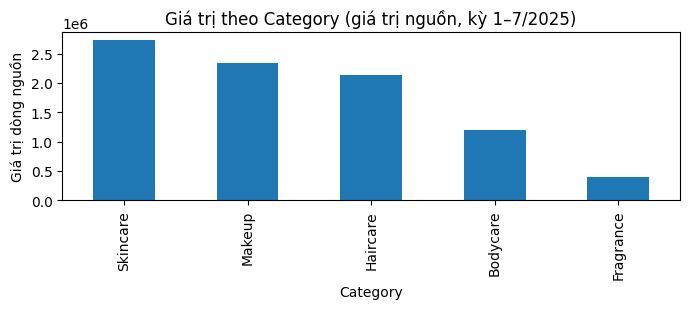

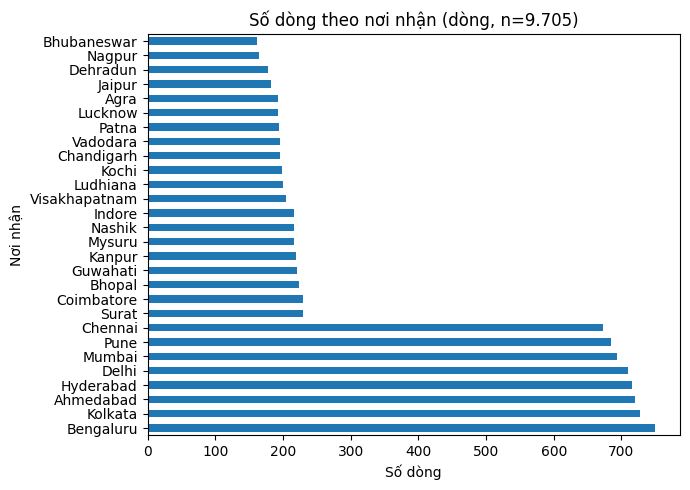

Top Category: {'Skincare': 2727493, 'Makeup': 2339309, 'Haircare': 2129527}
Top nơi nhận: {'Bengaluru': 749, 'Kolkata': 727, 'Ahmedabad': 720, 'Hyderabad': 715, 'Delhi': 710}


In [19]:
quy_mo_nhom = du_lieu.groupby('Category').Line_Amount.sum().sort_values(ascending=False)
ax = quy_mo_nhom.plot(kind='bar', figsize=(7, 3.2))
ax.set_title('Giá trị theo Category (giá trị nguồn, kỳ 1–7/2025)')
ax.set_xlabel('Category'); ax.set_ylabel('Giá trị dòng nguồn')
plt.tight_layout(); plt.show()
quy_mo_noi = du_lieu.groupby('To_Location').size().sort_values(ascending=False)
ax = quy_mo_noi.plot(kind='barh', figsize=(7, 5))
ax.set_title('Số dòng theo nơi nhận (dòng, n=9.705)')
ax.set_xlabel('Số dòng'); ax.set_ylabel('Nơi nhận')
plt.tight_layout(); plt.show()
print('Top Category:', quy_mo_nhom.head(3).to_dict())
print('Top nơi nhận:', quy_mo_noi.head(5).to_dict())


### Nhóm sản phẩm/nơi nhận lớn cỡ nào?

**Giải thích:** Skincare/Makeup/Haircare chiếm phần lớn giá trị; 28 nơi nhận phân tán, đông nhất ~749 dòng. Số phục vụ chọn nhóm xem xét ở phase sau; thiếu lợi nhuận/tồn kho nên chưa quyết định mua hàng.

In [20]:
dong_gop = du_lieu.groupby('Category').agg(dong=('Qty', 'size'), tri=('Line_Amount', 'sum')).sort_values('tri', ascending=False)
dong_gop['ty_trong'] = dong_gop.tri / dong_gop.tri.sum()
print(dong_gop.to_string())
print('SKU riêng theo nhóm:', du_lieu.groupby('Category').SKU_Code.nunique().to_dict())
print('Top nơi nhận:', du_lieu.groupby('To_Location').Line_Amount.sum().sort_values(ascending=False).head(5).to_dict())
print('Tỷ trọng trên tổng đầy đủ; không suy lợi nhuận/tồn kho/nhập hàng.')


           dong      tri  ty_trong
Category                          
Skincare   3337  2727493  0.310398
Makeup     2077  2339309  0.266221
Haircare   1957  2129527  0.242347
Bodycare   2072  1202561  0.136855
Fragrance   262   388201  0.044179
SKU riêng theo nhóm: {'Bodycare': 11, 'Fragrance': 2, 'Haircare': 10, 'Makeup': 10, 'Skincare': 17}
Top nơi nhận: {'Bengaluru': 678661, 'Kolkata': 676437, 'Hyderabad': 648387, 'Delhi': 635011, 'Mumbai': 630678}
Tỷ trọng trên tổng đầy đủ; không suy lợi nhuận/tồn kho/nhập hàng.


**Giải thích:** bảng cho đóng góp và tỷ trọng trên tổng đầy đủ theo nhóm hàng, số SKU riêng từng nhóm (tính thật, không chỉ khẳng định) và top nơi nhận. Dùng để chọn nhóm xem xét; thiếu lợi nhuận/tồn kho nên chưa quyết định nhập hàng.

In [21]:
wb_rieng = openpyxl.load_workbook(DATA, read_only=True, data_only=True)
tong_dl = {'dong': 0, 'qty': 0.0, 'tri': 0.0}
thang_dl, nhom_dl, noi_dl = {}, {}, {}
for ten in wb_rieng.sheetnames:
    dong = list(wb_rieng[ten].iter_rows(values_only=True))
    idx = {c: i for i, c in enumerate(dong[0])}
    for r in dong[1:]:
        if all(v is None for v in r): continue
        ban = r[idx['Sales_Date']]; ym = f'{ban.year}-{ban.month:02d}'
        q, t = r[idx['Qty']], r[idx['Line_Amount']]
        tong_dl['dong'] += 1; tong_dl['qty'] += q; tong_dl['tri'] += t
        for bang, khoa in [(thang_dl, ym), (nhom_dl, r[idx['Category']]), (noi_dl, r[idx['To_Location']])]:
            s = bang.setdefault(khoa, [0, 0.0, 0.0]); s[0] += 1; s[1] += q; s[2] += t
wb_rieng.close()
bang_pd = {
 'thang': du_lieu.groupby('__thang__').agg(d=('__excel_row__', 'size'), q=('Qty', 'sum'), t=('Line_Amount', 'sum')),
 'nhom': du_lieu.groupby('Category').agg(d=('__excel_row__', 'size'), q=('Qty', 'sum'), t=('Line_Amount', 'sum')),
 'noi': du_lieu.groupby('To_Location').agg(d=('__excel_row__', 'size'), q=('Qty', 'sum'), t=('Line_Amount', 'sum'))}
leches = []
for loai, doc_lap, cot_pd in [('thang', thang_dl, 'thang'), ('nhom', nhom_dl, 'nhom'), ('noi', noi_dl, 'noi')]:
    khoa_dl, khoa_pd = set(doc_lap), set(bang_pd[cot_pd].index)
    print(f'{loai}: doc lap {len(khoa_dl)} nhom | pandas {len(khoa_pd)} nhom')
    assert khoa_dl == khoa_pd, f'DUNG: nhom thieu/du loai {loai}'
    for khoa in sorted(khoa_dl):
        d, q, t = doc_lap[khoa]
        that = (int(bang_pd[cot_pd].loc[khoa, 'd']), float(bang_pd[cot_pd].loc[khoa, 'q']), float(bang_pd[cot_pd].loc[khoa, 't']))
        if (d, q, t) != that:
            leches.append((loai, khoa, (d, q, t), that))
print('Nhom lech so dong/Qty/trị:', leches or 'khong co')
assert not leches, f'DUNG: {len(leches)} nhom lech'
assert tong_dl == {'dong': 9705, 'qty': 13087.0, 'tri': 8787091.0}
print('Doc lap khop: tong + tung thang/Category/noi nhan (delta 0).')


thang: doc lap 7 nhom | pandas 7 nhom
nhom: doc lap 5 nhom | pandas 5 nhom
noi: doc lap 28 nhom | pandas 28 nhom
Nhom lech so dong/Qty/trị: khong co
Doc lap khop: tong + tung thang/Category/noi nhan (delta 0).


### Đọc độc lập có khớp?

**Giải thích:** lượt đọc thứ hai đi thẳng ô Excel bằng openpyxl (không qua bảng pandas), đối chiếu số dòng/Qty/trị từng tháng, từng Category, từng nơi nhận — gồm cả tập khóa (nhóm thiếu/dư là fail) — delta 0 toàn bộ. Đây là kiểm độc lập, không chép lại số.

In [22]:
ban_sao = du_lieu.copy()
ban_sao.loc[ban_sao[ban_sao.Category == 'Skincare'].index[0], 'Qty'] += 1
tong_sao = {'dong': len(ban_sao), 'qty': float(ban_sao.Qty.sum()), 'tri': float(ban_sao.Line_Amount.sum())}
bat_duoc = tong_sao != {'dong': 9705, 'qty': 13087.0, 'tri': 8787091.0}
print('Ban sao sua 1 Qty Skincare:', tong_sao, '->', 'BAT DUOC LECH' if bat_duoc else 'KHONG BAT DUOC')
assert bat_duoc, 'DUNG: kiem khong nhay khi du lieu doi'
assert len(du_lieu) == 9705 and float(du_lieu.Qty.sum()) == 13087.0, 'DUNG: bang that bi doi'
print('Bang that nguyen ven; kiem du nhay.')


Ban sao sua 1 Qty Skincare: {'dong': 9705, 'qty': 13088.0, 'tri': 8787091.0} -> BAT DUOC LECH
Bang that nguyen ven; kiem du nhay.


**Giải thích:** kiểm nhỏ trên bản sao: sửa 1 Qty thì đối chiếu phải báo lệch (bắt được), đồng thời bảng thật giữ nguyên. Không động file nguồn.

In [23]:
loi = []
def chot(ten, ky_vong, thuc_te):
    dat = ky_vong == thuc_te
    print(f'{ten}: kỳ vọng {ky_vong} | thực tế {thuc_te} → {"ĐẠT" if dat else "KHÔNG ĐẠT"}')
    if not dat: loi.append(ten)
chot('hash', 'fae7a6955da3f3166ef4766d26acc39b8fed7b8c763e077a83c015a6d4fc0bd8', sha_dau)
chot('tổng dòng', 9705, len(du_lieu))
chot('mã đơn / đa khách', (6246, 3459), (int(du_lieu.Order_ID.nunique()), int((du_lieu.groupby("Order_ID").Customer_ID.nunique() > 1).sum())))
chot('cờ 1 / mẫu hợp lệ', (574, 9705), (so_co_1, mau_hop_le))
chot('tổng Qty / giá trị', (13087.0, 8787091.0), (float(so_luong.sum()), float(gia_tri.sum())))
chot('đọc độc lập dòng/Qty/trị', (9705, 13087.0, 8787091.0), (tong_dl['dong'], tong_dl['qty'], tong_dl['tri']))
assert not loi, f'DỪNG: {loi}'
print('Kết luận: kỹ thuật ĐẠT; 3 phát hiện (đa khách/kênh đơn trị/cờ mức dòng) chờ xem bộ thực hành/tác giả.')
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == 'fae7a6955da3f3166ef4766d26acc39b8fed7b8c763e077a83c015a6d4fc0bd8'
print('Hash cuối run khớp — khóa bản.')


hash: kỳ vọng fae7a6955da3f3166ef4766d26acc39b8fed7b8c763e077a83c015a6d4fc0bd8 | thực tế fae7a6955da3f3166ef4766d26acc39b8fed7b8c763e077a83c015a6d4fc0bd8 → ĐẠT
tổng dòng: kỳ vọng 9705 | thực tế 9705 → ĐẠT
mã đơn / đa khách: kỳ vọng (6246, 3459) | thực tế (6246, 3459) → ĐẠT
cờ 1 / mẫu hợp lệ: kỳ vọng (574, 9705) | thực tế (574, 9705) → ĐẠT
tổng Qty / giá trị: kỳ vọng (13087.0, 8787091.0) | thực tế (13087.0, 8787091.0) → ĐẠT
đọc độc lập dòng/Qty/trị: kỳ vọng (9705, 13087.0, 8787091.0) | thực tế (9705, 13087.0, 8787091.0) → ĐẠT
Kết luận: kỹ thuật ĐẠT; 3 phát hiện (đa khách/kênh đơn trị/cờ mức dòng) chờ xem bộ thực hành/tác giả.
Hash cuối run khớp — khóa bản.


### Kết luận kiểm là gì?

**Giải thích:** bảng chốt gom đối chiếu kỹ thuật — sai là lỗi tại chỗ. Nguồn expected: dispatch cho sheet/header/dòng/hash; các đếm 6.246/3.459/574 và tổng là đếm mới của lượt này (supervisor đã đọc độc lập khớp, xem REVIEW). Phát hiện nghiệp vụ không thành điều kiện đòi dữ liệu sạch.